# Bressoux scenario setup

Prepares everything `main.py` needs for `data/bressoux/`, split in two:

- `inputs/` -- TRUE inputs, never overwritten by this notebook: the raw
  smart-meter data (`part-*.csv`), `coordinates.csv`, the topology builder
  (`network.py`), and the PV installation register (`pv_installations.csv`).
- `out/processed/` -- DERIVED data this notebook generates: `metadata.csv`,
  `load_profiles.csv`, `mv_load_profiles.csv`, and the cached PVGIS
  irradiance reference.

Steps:

1. builds the Bressoux LV/MV network (`inputs/network.py`) and sanity-checks it,
2. visualizes it on a real map (Folium),
3. generates household consumption profiles from the 33 real EAN smart meters
   plus per-household metadata (`out/processed/load_profiles.csv`, `metadata.csv`),
4. generates the 4 MV load facility profiles (`out/processed/mv_load_profiles.csv`),
5. materializes the PVGIS irradiance reference needed for PV production
   (`out/processed/pvgis_irradiance_quarter_hourly.parquet`).

Run this notebook with the **repository root** as the working directory
(same convention as `profil_conso.ipynb` / `analyze_Bressoux_data.ipynb`).

In [2]:
import json
import os
import random

import numpy as np
import pandas as pd
import folium
import matplotlib.pyplot as plt

from digital_twin.utils import (load_site_network, STEPS_PER_DAY,
                                bank_path_for, irradiance_path_for)
from digital_twin.data_processing.profiles import (
    build_consumption_bank, build_irradiance_reference,
    generate_household_metadata, generate_load_profiles,
)
from digital_twin.data_processing.equipment import (
    generate_equipment_table, sync_household_equipment,
)

DATA_PATH = "data/bressoux/"
INPUTS_DIR = os.path.join(DATA_PATH, "inputs")
OUT_DIR = os.path.join(DATA_PATH, "out/processed")
SEED = 42

# THE month of the scenario. It drives BOTH the real weeks the load profiles are
# drawn from AND the PV production month in main.py -- one setting, so charge and
# sun cannot end up on different seasons. Keep this equal to main.py's
# config['mois_simule'].
MOIS_SIMULE = 6

# Central battery b0, and the C-rate the domestic batteries derive from.
# Declared here as well so the scenario is described in one place.
SCENARIO = {
    "data_path": DATA_PATH,
    "seed": SEED,
    "mois_simule": MOIS_SIMULE,
    "trafo_sn_mva": 0.22,
    "street_weights": {"Rue Ernest Malvoz": 3.0},
    "mv_pv_installations": {"Paradis du Bouhay": 12.0},  # PV sur les charges MT, {nom -> kWc}
    "bss_park_e_kwh": 2600.0,
    "bss_park_p_kw": 595.0,
}

assert os.path.exists(os.path.join(INPUTS_DIR, "network.py")), (
    "inputs/network.py not found -- run this notebook with the repository root "
    "as the working directory."
)


## 1. Build the network

In [3]:
network = load_site_network(SCENARIO)
net = network["net"]

print(f"Buses: {len(net.bus)} (expected 346)")
print(f"Lines: {len(net.line)} (expected 341)")
print(f"Transformers: {len(net.trafo)} (expected 4)")
print(f"Residential buses: {len(network['buses'])} (expected 333)")
print(f"MV nodes: {len(network['mv_nodes'])} (expected 9)")
if network["warnings"]:
    print("Warnings:")
    for w in network["warnings"]:
        print(" -", w)
else:
    print("No topology warnings.")

Buses: 346 (expected 346)
Lines: 341 (expected 341)
Transformers: 4 (expected 4)
Residential buses: 333 (expected 333)
MV nodes: 9 (expected 9)
No topology warnings.


## 2. Visualize the network on a real map

In [4]:
def _bus_latlon(bus_id):
    geo = json.loads(net.bus.loc[bus_id, "geo"])
    lon, lat = geo["coordinates"]
    return lat, lon

m = folium.Map(location=_bus_latlon(network["mv_nodes"]["SLACK"]), zoom_start=16, tiles="OpenStreetMap")

# Residential LV buses
for (street, num), bus_id in network["buses"].items():
    lat, lon = _bus_latlon(bus_id)
    folium.CircleMarker(
        location=(lat, lon), radius=3, color="#4C78A8", fill=True, fill_opacity=0.7,
        popup=f"{street} {num} (bus {bus_id})",
    ).add_to(m)

# MV substations (with transformer)
for name in ["TROULOUETTE", "CIMETIERE BRESSOUX", "MALVOZ BRESSOUX", "GROTTES"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="red", icon="bolt", prefix="fa"),
        popup=f"Substation: {name} (bus {bus_id})",
    ).add_to(m)

# MV load nodes (large consumers, no transformer)
for name in network["mv_load_names"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="green", icon="building", prefix="fa"),
        popup=f"MV load: {name} (bus {bus_id})",
    ).add_to(m)

# Slack (external grid connection)
lat, lon = _bus_latlon(network["mv_nodes"]["SLACK"])
folium.Marker(
    location=(lat, lon), icon=folium.Icon(color="black", icon="plug", prefix="fa"),
    popup="SLACK (external grid)",
).add_to(m)

m

## 3. Generate household metadata + consumption profiles

Both files come out of **one** act: the draw decides which real week -- hence
which street and which month -- backs each `profile_id`, so `metadata.csv` and
`load_profiles.csv` are written together by `generate_load_profiles`.

The profiles are drawn from the **monthly bank** of real EAN weeks, restricted
to `MOIS_SIMULE`. That is what keeps the loads on the same season as the PV:
`metadata['source_month']` records it, and the twin warns if a run simulates a
different month.

One household **per LV charge bus**: `metadata` carries the assignment in a
`bus_id` column, so the twin looks it up instead of drawing it again at run
time. That second draw used to leave 73% of the buses with a load bit-identical
to a neighbour's, peaking at the same instant.


In [5]:
# Bank of every complete real calendar week, tagged by month/season/street.
# Slow (it reads the full raw meter file), so it is skipped when already there --
# delete the parquet to force a rebuild.
bank_path = bank_path_for(DATA_PATH)
if os.path.exists(bank_path):
    bank = pd.read_parquet(bank_path)
    print(f"Banque deja materialisee : {bank_path} ({len(bank)} semaines)")
else:
    bank = build_consumption_bank(data_path=DATA_PATH)

print(f"\nSemaines disponibles pour le mois {MOIS_SIMULE} : "
      f"{int((bank['month'] == MOIS_SIMULE).sum())}")


Banque deja materialisee : data/bressoux\out\processed\consumption_bank_real_weeks.parquet (1345 semaines)

Semaines disponibles pour le mois 6 : 133


In [6]:
# One household per LV charge bus, and metadata carries the assignment
# (bus_id) rather than leaving it to a draw inside the twin at run time.
metadata = generate_household_metadata(network)

households, metadata, load_warnings = generate_load_profiles(
    MOIS_SIMULE, metadata, config=SCENARIO, data_path=DATA_PATH)

for w in load_warnings:
    print(w)
print(f"\nhouseholds: {households.shape[0]} steps x {households.shape[1]} profiles -> "
      f"{os.path.join(OUT_DIR, 'load_profiles.csv')}")
print(f"metadata: {len(metadata)} rows -> {os.path.join(OUT_DIR, 'metadata.csv')}")
print(f"mois d'origine des profils : {sorted(metadata['source_month'].dropna().unique())}")
print(f"affectation menage -> bus  : {metadata['bus_id'].nunique()} bus BT, 1:1")
metadata.head()


[LOAD/draw] 333 profile(s) drawn from 133 real week(s) of month 6: 133/133 distinct week(s) used, max reuse 3x, 200 profile(s) jittered.

households: 672 steps x 333 profiles -> data/bressoux/out/processed\load_profiles.csv
metadata: 333 rows -> data/bressoux/out/processed\metadata.csv
mois d'origine des profils : [np.int64(6)]
affectation menage -> bus  : 333 bus BT, 1:1


,profile_id,bus_id,constellation,building_type,heat_pump,electric_water_heating,electric_vehicle_type,n_persons,pv_system_size_kwp,battery_size_kwh,source_street,source_month,source_week_start,source_ean_index
0,0,9,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-16T00:00:00+00:00,26
1,1,10,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-23T00:00:00+00:00,28
2,2,11,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-02T00:00:00+00:00,25
3,3,12,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,6,2025-06-02T00:00:00+00:00,5
4,4,13,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Rue Ernest Malvoz,6,2025-06-30T00:00:00+00:00,30


All scenario columns (`heat_pump`, `electric_water_heating`, `pv_system_size_kwp`,
`battery_size_kwh`, `n_persons`, `constellation`, `building_type`,
`electric_vehicle_type`) default to `False`/`0.0`/unknown — no household is
equipped with anything yet. These get edited later to define different
scenarios (e.g. flip flags on a subset of households) without needing to
regenerate the profiles themselves.

This update is to be done later. Do a small analysis as well of the households composition afterwards. Add profiles of different assets here using resflex package.

In [7]:
metadata[["heat_pump", "electric_water_heating"]].value_counts()

heat_pump  electric_water_heating
False      False                     333
Name: count, dtype: int64

## 4. Generate the MV load facility profiles

The 4 MV load facilities (rest home, school, sports hall, horticultural
centre) are large consumers connected directly at MV, each with its own
deterministic day/time profile (not drawn from the residential EAN data).
Ported from the historical `profil_conso.ipynb`: pure electricity consumption
only (lighting, IT, ventilation, pumps, lifts, kitchen) -- space/water heating
is excluded (a different energy vector).

In [8]:
random.seed(SEED)

N_PER_WEEK = 7 * 96
_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
time_index = [
    f"{_days[step // 96]} {(step % 96) * 15 // 60:02d}:{(step % 96) * 15 % 60:02d}"
    for step in range(N_PER_WEEK)
]


def get_mr_power(day_of_week, time_val):
    """Rest home ('Paradis du Bouhay') -- lighting, kitchen, lifts, cold rooms
    and auxiliaries. Space/water heating excluded (separate energy vector)."""
    power = 28.0
    is_weekend = day_of_week >= 5
    if 6.5 <= time_val < 11.5:
        power = 42.0
    elif 11.5 <= time_val < 14.0:
        power = 58.0
    elif 14.0 <= time_val < 17.5:
        power = 38.0
    elif 17.5 <= time_val < 20.0:
        power = 48.0
    elif 20.0 <= time_val < 22.5:
        power = 34.0
    if is_weekend:
        power *= 0.92
    return power * random.uniform(0.96, 1.04)


def get_ecole_power(day_of_week, time_val):
    """School ('Groupe Scolaire') -- lighting, IT, ambient ventilation. Heating
    excluded."""
    is_weekend = day_of_week >= 5
    is_wednesday = day_of_week == 2
    if is_weekend:
        return 0.8 * random.uniform(0.95, 1.05)
    if 7.5 <= time_val < 8.5:
        return 8.0 * random.uniform(0.95, 1.05)
    elif 8.5 <= time_val < 12.0:
        return 12.0 * random.uniform(0.95, 1.05)
    elif 12.0 <= time_val < 13.5:
        return 9.0 * random.uniform(0.95, 1.05)
    elif 13.5 <= time_val < 16.0:
        return (1.5 if is_wednesday else 11.0) * random.uniform(0.95, 1.05)
    elif 16.0 <= time_val < 18.0:
        return 4.0 * random.uniform(0.95, 1.05)
    else:
        return 1.2 * random.uniform(0.95, 1.05)


def get_hall_sport_power(day_of_week, time_val):
    """Sports hall ('Omnisport BX') -- track lighting and ventilation. Shower
    water heating excluded."""
    is_weekend = day_of_week >= 5
    if not is_weekend:
        if 8.0 <= time_val < 16.0:
            return 5.0 * random.uniform(0.92, 1.08)
        elif 16.0 <= time_val < 17.5:
            return 8.0 * random.uniform(0.95, 1.05)
        elif 17.5 <= time_val < 22.5:
            return 22.0 * random.uniform(0.95, 1.05)
        else:
            return 1.5 * random.uniform(0.95, 1.05)
    else:
        if 8.5 <= time_val < 21.5:
            return 18.0 * random.uniform(0.93, 1.07)
        else:
            return 1.8 * random.uniform(0.95, 1.05)


def get_horticole_power(day_of_week, time_val):
    """Horticultural centre ('Plantations') -- grow lighting, irrigation pumps,
    greenhouse vents. Greenhouse heating excluded."""
    is_weekend = day_of_week >= 5
    base_tech = 2.5 if is_weekend else 3.5
    if 7.5 <= time_val < 16.5:
        activity = 8.0 if not is_weekend else 1.5
        return (base_tech + activity) * random.uniform(0.95, 1.05)
    else:
        return base_tech * random.uniform(0.95, 1.05)


mv_load_profiles_kw = {name: [] for name in network["mv_load_names"]}
for step in range(N_PER_WEEK):
    dow = step // 96
    time_val = (step % 96) * 15 / 60.0
    mv_load_profiles_kw["Paradis du Bouhay"].append(get_mr_power(dow, time_val))
    mv_load_profiles_kw["Groupe Scolaire"].append(get_ecole_power(dow, time_val))
    mv_load_profiles_kw["Omnisport BX"].append(get_hall_sport_power(dow, time_val))
    mv_load_profiles_kw["Plantations"].append(get_horticole_power(dow, time_val))

mv_load_profiles = pd.DataFrame(mv_load_profiles_kw, index=time_index) / 1000.0  # kW -> MW
mv_load_profiles.index.name = "week_step"
mv_load_profiles.to_csv(os.path.join(OUT_DIR, "mv_load_profiles.csv"))
print(f"mv_load_profiles: {mv_load_profiles.shape} -> "
      f"{os.path.join(OUT_DIR, 'mv_load_profiles.csv')}")
mv_load_profiles.describe()

mv_load_profiles: (672, 4) -> data/bressoux/out/processed\mv_load_profiles.csv


,Paradis du Bouhay,Plantations,Omnisport BX,Groupe Scolaire
count,672.000000,672.000000,672.000000,672.000000
mean,0.037324,0.005527,0.008282,0.003518
std,0.009468,0.003652,0.008015,0.004150
min,0.024823,0.002377,0.001425,0.000760
25%,0.028345,0.003393,0.001556,0.000830
50%,0.036944,0.003575,0.004937,0.001204
75%,0.042705,0.011013,0.017562,0.004056
max,0.060176,0.012071,0.023059,0.012589


Should be validated.

## 5. Generate the PV irradiance reference

Needed by `process_data` to build `pv_profiles` from
`inputs/pv_installations.csv` (see `digital_twin.data_processing.pv.build_pv_production`).
Fetched once from PVGIS and cached -- skipped if already materialized.

In [9]:
irradiance_path = irradiance_path_for(DATA_PATH)

if os.path.exists(irradiance_path):
    print(f"Already materialized: {irradiance_path}")
else:
    # SCENARIO, pas seulement le chemin : la latitude/longitude est deduite du
    # centroide des bus BT du reseau (utils.site_centroid), donc la fonction a
    # besoin de savoir quel site charger.
    build_irradiance_reference(SCENARIO)


Already materialized: data/bressoux\out\processed\pvgis_irradiance_quarter_hourly.parquet


## 6. Sanity check plots

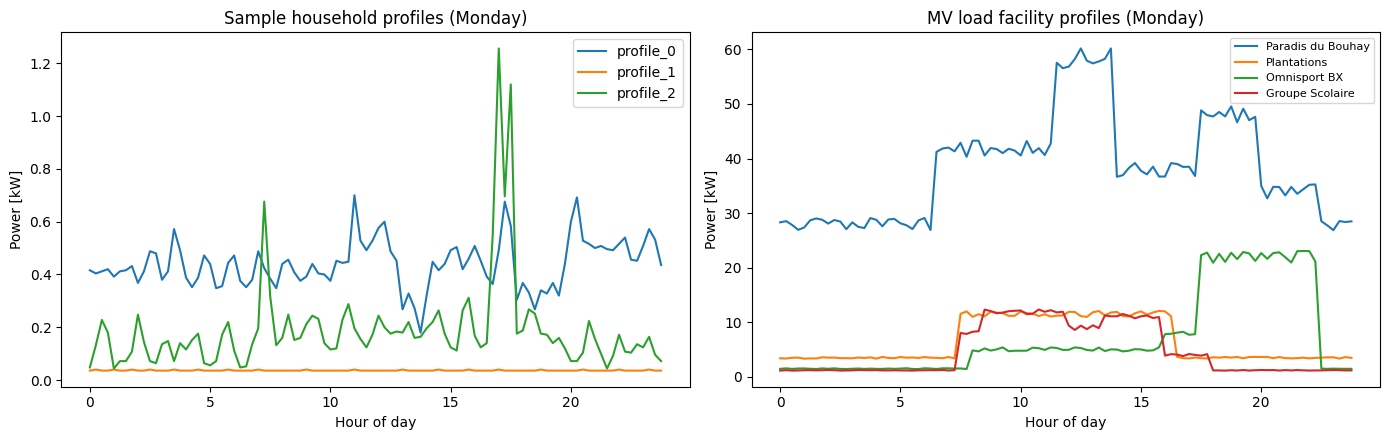

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

t = np.arange(STEPS_PER_DAY) * 0.25
for i in range(3):
    day_vals = households[f"profile_{i}"].to_numpy()[:STEPS_PER_DAY] * 1000  # MW -> kW
    axes[0].plot(t, day_vals, label=f"profile_{i}")
axes[0].set_title("Sample household profiles (Monday)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Power [kW]")
axes[0].legend()

for name in network["mv_load_names"]:
    day_vals = mv_load_profiles[name].to_numpy()[:STEPS_PER_DAY] * 1000  # MW -> kW
    axes[1].plot(t, day_vals, label=name)
axes[1].set_title("MV load facility profiles (Monday)")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Power [kW]")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_profiles.png"), dpi=300)
plt.show()

## 7. Place the equipment (PV + domestic batteries)

`equipment.csv` is the **one** register the scenario hangs on: one row per
equipable bus (333 LV + 4 MV load facilities), carrying the PV sizes and the
domestic battery ids/capacities. It replaces the two files that used to live in
`inputs/` (`pv_installations.csv`, `bss_shares.csv`).

Both optional layers of the twin switch on from its **content**: a bus with
`pv_system_size_kwp > 0` gets PV, a bus with `battery_size_kwh > 0` gets a
battery `b1..bn`. The central battery `b0` is *not* a row here -- it sits on an
MV node and takes its specs from `config`.


In [11]:
equipment = generate_equipment_table(SCENARIO)

# metadata porte pv_system_size_kwp / battery_size_kwh (schema MAS4TE), mais
# c'est la table AU NIVEAU BUS qui fait foi. On projette, sinon ces colonnes
# restent a 0.0 et lisent "aucune batterie" pour des bus qui en portent une.
metadata = sync_household_equipment(metadata, equipment)
metadata.to_csv(os.path.join(OUT_DIR, "metadata.csv"), index=False)

n_pv = int((equipment["pv_system_size_kwp"].fillna(0.0) > 0).sum())
n_bat = int((equipment["battery_size_kwh"].fillna(0.0) > 0).sum())
print(f"equipment.csv : {len(equipment)} bus equipables -> "
      f"{os.path.join(OUT_DIR, 'equipment.csv')}")
print(f"  PV        : {n_pv} installations, "
      f"{equipment['pv_system_size_kwp'].fillna(0.0).sum():.1f} kWc au total")
print(f"  batteries : {n_bat} domestiques (b1..b{n_bat}), "
      f"{equipment['battery_size_kwh'].fillna(0.0).sum():.0f} kWh")
print(f"  + b0 centrale : {SCENARIO['bss_park_e_kwh']:.0f} kWh / "
      f"{SCENARIO['bss_park_p_kw']:.0f} kW sur un noeud MT")
print(f"metadata resynchronisee : "
      f"{int((metadata['pv_system_size_kwp'].fillna(0) > 0).sum())} menages avec PV, "
      f"{int((metadata['battery_size_kwh'].fillna(0) > 0).sum())} avec batterie")

equipment[equipment["battery_size_kwh"].fillna(0.0) > 0][
    ["bus_id", "street", "num", "pv_system_size_kwp", "battery_id", "battery_size_kwh"]
].head()


equipment.csv : 337 bus equipables -> data/bressoux/out/processed\equipment.csv
  PV        : 31 installations, 102.0 kWc au total
  batteries : 20 domestiques (b1..b20), 200 kWh
  + b0 centrale : 2600 kWh / 595 kW sur un noeud MT
metadata resynchronisee : 30 menages avec PV, 20 avec batterie


,bus_id,street,num,pv_system_size_kwp,battery_id,battery_size_kwh
8,13,Rue Ernest Malvoz,93.0,3.0,b1,10.0
10,15,Rue Ernest Malvoz,89.0,3.0,b2,10.0
14,19,Rue Ernest Malvoz,77.0,3.0,b3,10.0
32,37,Rue Ernest Malvoz,29.0,3.0,b4,10.0
34,39,Rue Ernest Malvoz,25.0,3.0,b5,10.0


## 8. The network once equipped

Same map as section 2, with the scenario's equipment on top: PV installations in
orange, domestic batteries in green, and the central battery `b0` on its MV node.
Comparing the two maps shows what the scenario actually added -- and where the
clusters landed, which is what drives local overvoltage.


In [13]:
bss_bus_name = SCENARIO.get("bss_bus", "MALVOZ BRESSOUX")
equipped_pv = equipment[equipment["pv_system_size_kwp"].fillna(0.0) > 0]
equipped_bat = equipment[equipment["battery_size_kwh"].fillna(0.0) > 0]
pv_buses = set(equipped_pv["bus_id"].astype(int))
bat_by_bus = {int(r.bus_id): r for r in equipped_bat.itertuples()}

m2 = folium.Map(location=_bus_latlon(network["mv_nodes"]["SLACK"]),
                zoom_start=16, tiles="OpenStreetMap")

# Every LV bus, greyed out unless it carries something
for (street, num), bus_id in network["buses"].items():
    lat, lon = _bus_latlon(bus_id)
    has_pv, bat = bus_id in pv_buses, bat_by_bus.get(bus_id)
    if bat is not None:
        color, radius, label = "#2E8B57", 6, f"{bat.battery_id} -- {bat.battery_size_kwh:.0f} kWh"
    elif has_pv:
        color, radius, label = "#E8730C", 5, "PV"
    else:
        color, radius, label = "#4C78A8", 2, "aucun equipement"
    if has_pv and bat is not None:
        label = f"PV + {label}"
    folium.CircleMarker(
        location=(lat, lon), radius=radius, color=color, fill=True, fill_opacity=0.85,
        popup=f"{street} {num} (bus {bus_id}) -- {label}",
    ).add_to(m2)

# MV load facilities: PV-capable too (the rest home carries a large array)
for name in network["mv_load_names"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    row = equipment[equipment["bus_id"] == bus_id]
    kwp = float(row["pv_system_size_kwp"].fillna(0.0).iloc[0]) if len(row) else 0.0
    folium.Marker(
        location=(lat, lon),
        icon=folium.Icon(color="orange" if kwp > 0 else "green", icon="building", prefix="fa"),
        popup=f"MV load: {name} (bus {bus_id})" + (f" -- PV {kwp:.0f} kWc" if kwp else ""),
    ).add_to(m2)

# Central battery b0
b0_bus = network["mv_nodes"][bss_bus_name]
lat, lon = _bus_latlon(b0_bus)
folium.Marker(
    location=(lat, lon), icon=folium.Icon(color="darkgreen", icon="car-battery", prefix="fa"),
    popup=(f"b0 -- batterie centrale (bus {b0_bus}, {bss_bus_name})<br>"
           f"{SCENARIO['bss_park_e_kwh']:.0f} kWh / {SCENARIO['bss_park_p_kw']:.0f} kW"),
).add_to(m2)
folium.Circle(location=(lat, lon), radius=60, color="#2E8B57", fill=False, weight=2).add_to(m2)

legend = (
    '<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:white;'
    'padding:10px 14px;border:1px solid #999;border-radius:4px;font-size:13px">'
    f'<b>Equipement du scenario</b><br>'
    f'<span style="color:#E8730C">&#9679;</span> PV ({n_pv})<br>'
    f'<span style="color:#2E8B57">&#9679;</span> batterie domestique ({n_bat})<br>'
    f'<span style="color:#4C78A8">&#9679;</span> bus BT sans equipement<br>'
    f'<span style="color:#2E8B57">&#9711;</span> b0 centrale sur {bss_bus_name}'
    '</div>'
)
m2.get_root().html.add_child(folium.Element(legend))
m2


## Next step

Everything `main.py` needs is now under `out/processed/`:
`equipment.csv`, `metadata.csv`, `load_profiles.csv`, `mv_load_profiles.csv`,
`consumption_bank_real_weeks.parquet` and
`pvgis_irradiance_quarter_hourly.parquet`. With `inputs/network.py` in place,
run the digital twin:

```bash
python main.py
```

`pv_profiles` and `schedules_BSS` are **not** files: they are rebuilt on every
call from `equipment.csv` + the irradiance + the loads, so a change of scenario
means editing the equipment table, not a pile of profile files.

Keep `config['mois_simule']` in `main.py` equal to `MOIS_SIMULE` above. If they
differ, the run still works but the twin raises a `[LOAD/saison]` warning: the
loads would come from one month and the sun from another.

Set `config['save'] = True` (the default) to write a Markdown report
(summary/violations/warnings) to `data/bressoux/out/results/`.
